<h1><center>2D Ising Model Simulation: The Wolff Algorithm</center></h1>
<h2><center>Asfar Ahmad</center></h2>
<center>The Ising Model is used to study particle spins in a lattice structure and can be used to find phase transition points. In this project, I will be investigating how the mean energy and spin of a lattice of electrons evolves over time with the Wolff Algorithm. I will be using this information, along with the susceptibility and heat capacity, to find the critical temperature of the 2D Ising Model.</center>

<h2><center>What is the Ising Model?</center></h2>

![Image of Lattice](https://stanford.edu/~jeffjar/statmech/ising.jpg)
(Images Credit to Stanford University: https://stanford.edu/~jeffjar/statmech/ising.jpg)

<center>Particles, specifically electrons, have a spin (+1 or -1). Electrons will orient themselves in a spin that minimizes their potential energy. The energy of an electron in a spin state, $\mu$, depends on the spins of the nearest neighbor electrons in the lattice. If the nearest neighbors' spins are mostly opposing, then the potential energy is high. Otherwise, the potential energy is low. The Ising Model gives an equation for a particle's potential energy by considering spins of particles directly on top of, on the bottom of, and to the left and right of the particle in question. This is the equation for the energy of a particle in state $\mu$: <center>
<center>
    $E_{\mu}=\sum_{<i,j>}-J\sigma_{i}\sigma_{j}$
    <br>
    <br>
    J is the coupling constant: <br>
    $J_{ij}\gt0$ is a ferromagnet, <br>
    $J_{ij} \lt 0$ is antiferromagnet, and <br>
    $\sigma$ is the spin configuration. <br>
    $<i,j>$ means that only the nearest (top, bottom, left, and right) particles are summed to find the energy.
    <br>NOTE: This equation only works when there is not an external field is acting on the system. To learn more about how to handle external fields, read the Stanford article here: https://stanford.edu/~jeffjar/statmech/intro4.html
    
<br>

<h2><center>The Wolff Algorithm</center></h2>
<center>The Wolff Algorithm is based on the Swendsen–Wang (SW) Algorithm. Both can be used to determine how the average energy and average spin of electrons in a lattice change (with temperature held constant) as the number of iterations increases.NOTE: this is NOT the change over time; rather, the algorithms can be used over many iterations to find the equilibrium state). The algorithms can be used at many different temperatures to find the phase transition point.</center>
<br>
<h3>The Swendsen–Wang (SW) Algorithm</h3>
The SW Algorithm divides the lattice into many different clusters of the same spin. In the context of electrons, they would be grouped into clusters of +1 spin and -1 spin. For example, suppose we had an electron with +1 spin. Then, the nearest electrons of +1 spin would have a chance to be added to the cluster.

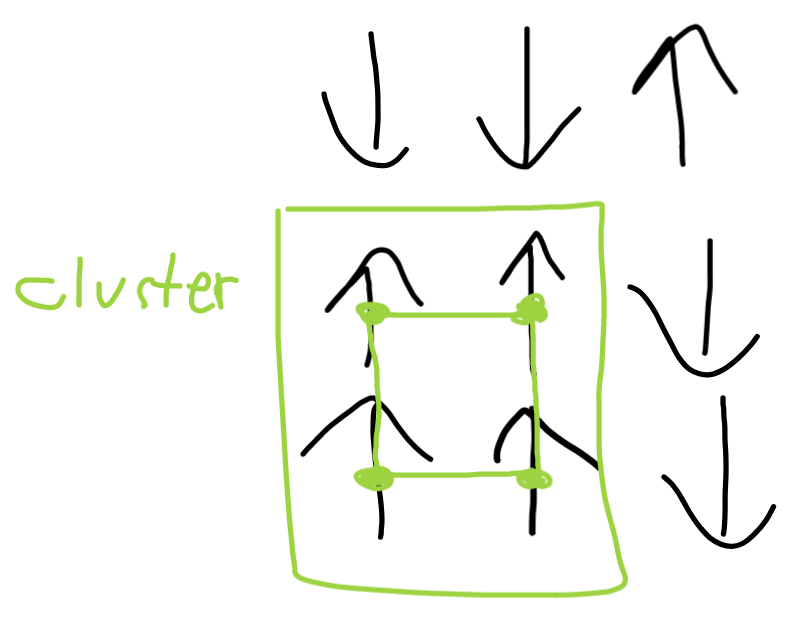

In this example, we started at the center electron, which has a +1 spin, so it forms a bond with the nearest electrons of +1 spin (left and bottom) and creates a cluster of 4 electrons with +1 spin (note that the diagonals are not counted as "near" the center; if we only used the center electrons' bonds we would have a cluster of size 3. However, the nearest neighbors also form bonds with their own nearest neighbors, increasing the size of the cluster from 3 to 4). Note that, in reality, the probability that these bonds form is NOT 100%. As the temperature increases, the kinetic energy of electrons increase. With more kinetic energy, it is less likely that bonds between electrons of parallel spins will form. The equation for the probability of a bond forming between 2 near electrons (eletrons i and j) of parallel spin is:
<center>$p_{ij}=1-e^{-2\beta J}$</center>
<br><center>where $\beta=\frac{1}{kT}$, where k is the Boltzmann constant and T is the temperature.</center>
<br> NOTE: For the Ising model, T is usually in $\frac{J}{k}$, as opposed to just Joules, so, I will assume T to be in units of $\frac{J}{k}$ and will be using $\beta=\frac{1}{T}$ instead of $\beta=\frac{1}{kT}$.

Thus, clusters are created through the entire lattice based on the probability of the electrons of parallel spins bonding. The spins of each cluster are independent of spins of other clusters.* So, looking at each cluster individually, we can randomly choose what spin they get (i.e., there is a 50% chance we change a cluster to +1 spin, and a 50% chance we change it to -1 spin). After many iterations, this random choosing of spins of clusters will result in the equilibrium state.

In summary, the SW Algorithm divides electrons in the lattice into clusters, randomly changes their spins, then repeats until equilibrium is reached. 
<br><br>
*This is due to the Fortuin-Kasteleyn mapping of the Potts Model to the random cluster model; read more about it here: https://en.wikipedia.org/wiki/Random_cluster_model

<h3>The Wolff Algorithm</h3>

The difference between the Wolff Algorithm and SW Algorithm is that the Wolff Algorithm only divides the lattice into one cluster and has a 100% chance of changing/inverting the spins within the cluster (as opposed to the SW Algorithm, which only changes spin with a 50% probability). <br>

The Wolff Algorithm has the benefit of being more efficient than the SW Algorithm near the critical temperature.

> <center>What is the Critical Temperature? </center><br>
> At low temperatures, the electrons' spins will be mostly ordered because there is not much kinetic energy to disorganize them. At high temperatures, their spins will be mostly disorded because of the large amount of kinetic energy. The critical temperature is the turning point, where the entire lattice goes from being mostly ordered to mostly disordered. For 2D, the critical temperature, $T_{c}$, is known to be about 2.27 ($\frac{J}{k_B}$), which we will be trying to approximate in this simulation. See the derivation for $T_{c}$ here:<br> https://en.wikipedia.org/wiki/Square_lattice_Ising_model. <br>

Here are the steps to the Wolff Algorithm:
1. Select an electron, i, and determine its spin.
2. Look at the neighoring electrons, j:
> If the spin of j is the same as i, and the link between i and j has not been tried before, then there is a probability $p_{ij}$ of adding it to the cluster. If the spins of i and j are different, then don't add it to the cluster.
3. For the neighboring electrons, j, that were added to the cluster, look at j's nearest neighbors, k. Use step 2 to determine whether to add k to the cluster.
4. Repeat steps 2 and 3 until all nearest neighbors to every electron in the cluster have either been added to the cluster or disregarded.
5. Invert the spin of all electrons in the cluster. 
> NOTE: We can remove step 5 by inverting the electron's spin as soon as it is added to the cluster in step 2.
6. Disregard the old cluster and repeat steps 1-5: iterate through many different clusters, inverting their spins until equilibrium is reached.

<h2><center>Necessary Data Structures</center></h2>

In this simulation, two different data structures will be used to hold the lattice data:
1. NumPy Arrays
> Arrays are very fast, and will be necessary to perform quick computations of the energy. Arrays of only two values, +1 and -1, can quickly be visualized using MatPlotLib.
2. NetworkX Graphs
> Graphs will hold more data than NumPy arrays, but will be slower to perform computations on. They will also require significantly more code to visualize, and take longer to update, so they are not ideal to visualize the evolution of electron spins.



Now, we are finally ready to start the code. <br>
Here, the necessary libraries are imported.

In [8]:
import numpy as np                                            # Calculations
import matplotlib.pyplot as plt                               # Plotting
from numba import jit                                         # Increases efficiency of algorithm    
import time                                                   # Can be used to delay algorithm for slow computers
%matplotlib inline
from IPython.display import clear_output                      # Used to display evolving lattice
from scipy.ndimage import convolve, generate_binary_structure # Convolutions are used to isolate nearest neighbors
import networkx as nx                                         # Represents the lattice as a graph, with bonds as the links
                                                              # and electrons as the nodes.

In the following code, an initial lattice of 50x50 random spins is created.

In [9]:
N = 50                               # Size of the lattice.
random_NxN = np.random.random((N,N)) # Generate random numbers in [0.0,1.0) in an array size NxN

# randomized lattice
lattice_r = np.zeros((N, N))
lattice_r[random_NxN >= 0.5] = 1
lattice_r[random_NxN < 0.5]  = -1


Visualizing the lattice.

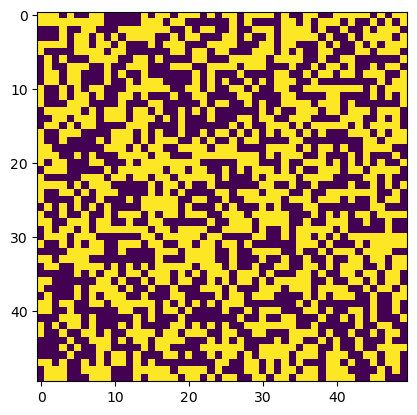

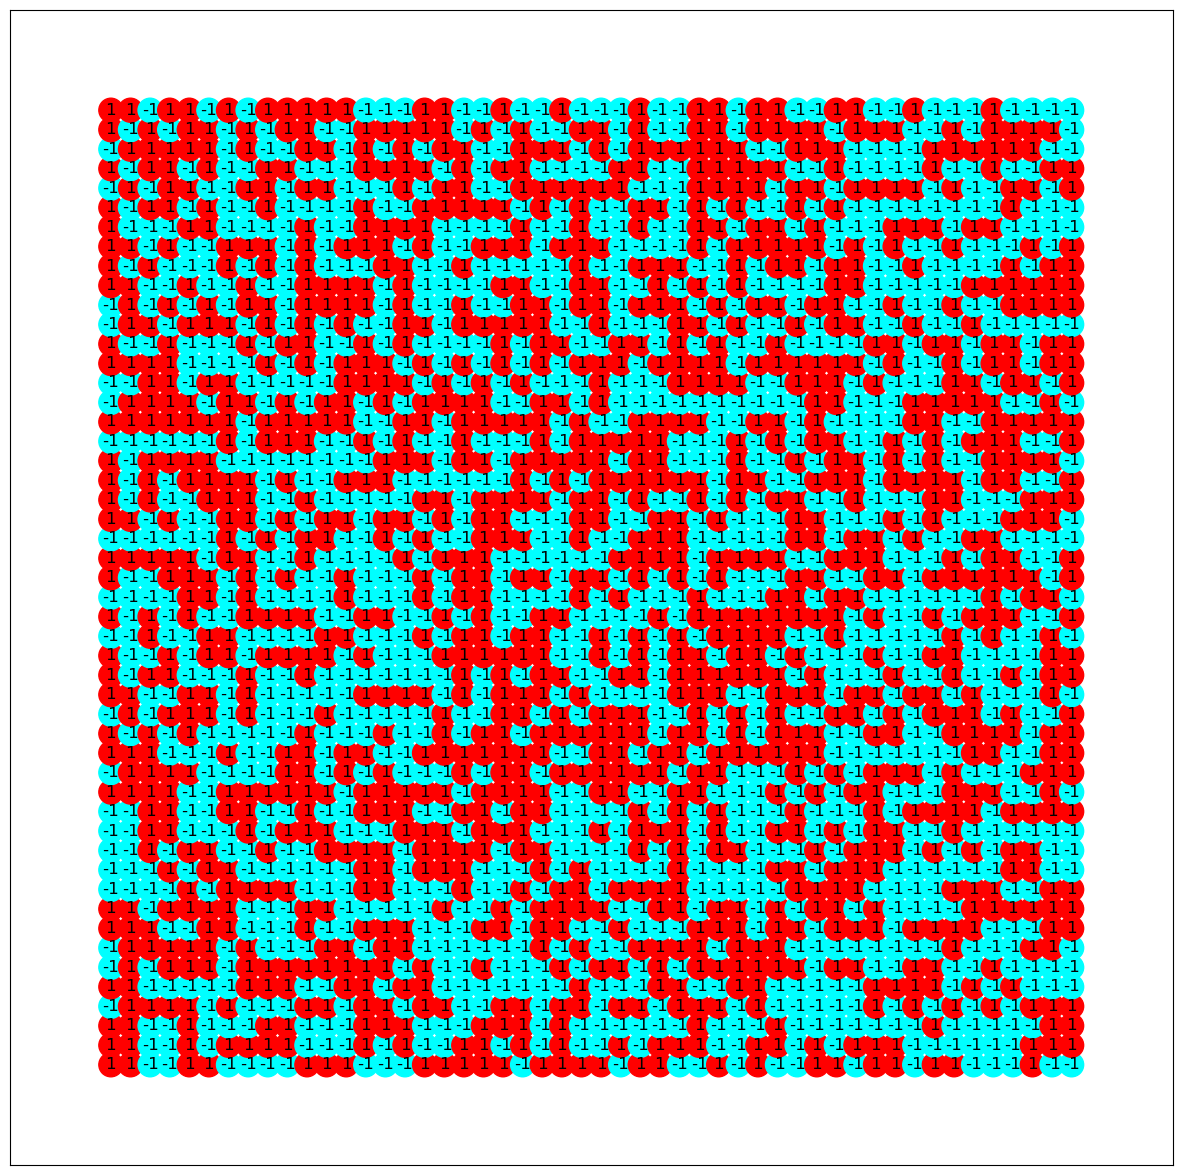

In [10]:
%matplotlib inline
# Use the MatPlotLib imshow function to display lattice array (Note that (0,0) is at the top left)
plt.imshow(lattice_r)
plt.show()

#######################################################################################################
# Function that takes in a lattice array of electron spins and outputs a corresponding NetworkX graph #
#    Inputs:                                                                                          #
#        - lattice: the array of electron spins                                                       #
#    Outputs:                                                                                         #
#        - G: the lattice as a NetworkX graph                                                         #
#        - position: the position of the electrons in the lattice                                     #
#        - color_map: list of colors in the graph (+1 is red -1 is blue)                              #
#######################################################################################################
def lattice_array2graph(lattice):
    num_rows = lattice.shape[0]
    num_cols = lattice.shape[1]
    
    # Create lattice graph
    G = nx.grid_2d_graph(num_rows,num_cols)

    # Change the nodes to the corresponding electrons in the lattice
    for row in range(0, num_rows):
        for col in range(0, num_cols):
            G.add_node((row, col), **{'spin': int(lattice[row][col]), 'is_bonded':False}, pos=(row,col))
            
    # Get positions
    position = nx.get_node_attributes(G,'pos')

    # Get colors in the color_map
    color_map = []
    for node in G.nodes:
        if (G.nodes[node]['spin'] == 1):
            color_map.append('red')
        else:
            color_map.append('cyan')
            
    # Set default attribute of the edges
    for edge in G.edges:
        G.edges[edge]['has_been_checked'] = False
            
    return G, position, color_map

# Display a NetworkX graph (Note that (0,0) is at the bottom left)
lat_graph, pos, color = lattice_array2graph(lattice_r)
plt.figure(figsize=(15,15))

node_labels = nx.get_node_attributes(lat_graph,'spin')
nx.draw_networkx_labels(lat_graph, pos, labels = node_labels)
nx.draw_networkx(lat_graph, pos = pos, node_color = color, with_labels=False)

These are both visualizations of the same lattice. The first one uses MatPlotLib's imshow function and is very fast. The second one draws a NetworkX graph, where a +1 is red and a -1 spin is blue, and is slow. In this simulation, MatPlotLib's imshow function will be used to visualize the algorithm as it goes through the iterations (if show_lattice is set to True), and the NetworkX graph will be displayed as the final step.


A fast way to find the nearest neighbors (with the lattice array, not the graph) is with a convolution matrix, so that only the top, bottom, left and right electrons are considered.

In [448]:
conv = generate_binary_structure(2, 1) 
conv[1][1] = False
print("The Convolution Matrix:\n\n", conv)

The Convolution Matrix:

 [[False  True False]
 [ True False  True]
 [False  True False]]


Now we can define an energy function using the convolution matrix.

In [449]:
#######################################################################################
# energy gives the total energy contained in a lattice array                          #
# Inputs:                                                                             #
#    - lattice: an array containing spins of all electrons in the lattice             #
#    - J: coupling constant of the system                                             #
# Output:                                                                             #
#    - Total energy of the system                                                     #
#######################################################################################
@jit
def energy(lattice, J):
    arr = -lattice * convolve(lattice, conv, mode='constant', cval=0) * J / 2 # Divide by 2 to avoid double counting
    return arr.sum()

Wolff Algorithm Implementation

In [450]:
########################################################################################
# Wolff uses the Wolff Algorithm to approximate the equilibrium state of the lattice   #
#    and display a plot of the evolving lattice if show_lattice is set to True.        #
# Inputs:                                                                              #
#    - lattice: an array containing spins of all electrons in the lattice              #
#    - iterations: the number of times to repeat step 6 before terminating             #
#    - J: The coupling constant                                                        #
#    - T: The temperature in J / k_B                                                   #
#    - show_lattice: boolean, will show the lattice evolving if true                   #
# Output:                                                                              #
#    - lattice_c: array of electron spins of the lattice after all iterations are done #
#    - net_spin: array of net electron spins at each iteration                         #
#    - net_energy: array containing net lattice energy for each iteration              #
########################################################################################
@jit(parallel=True)
def Wolff(lattice, iterations, J, T, show_lattice):
    # NOTE: beta = 1/(k_B*T), but we dont include k because T is in units of J/k_B
    BJ = J / T
    num_rows, num_cols = lattice.shape                           # Dimensions of the lattice
    prob = 1 - np.exp(-2 * BJ)                                   # Probability of forming bond with a neighboring particle
    net_spin = np.zeros(iterations+1)                            # Holds the net spin of the full lattice at each iteration
    net_energy = np.zeros(iterations+1)                          # Holds the total energy at each iteration
    lattice_c = np.copy(lattice)                                 # Copy the lattice so the original lattice is unaltered
    lattice_G = lattice_array2graph(lattice_c)[0]                # Lattice as a graph
    
    # Calculate the initial net_spin and net_energy
    # initial net_spin
    for node in lattice_G:
        net_spin[0] += lattice_G.nodes[node]['spin']
    
    # initial energy
    net_energy[0] = energy(lattice_c, J)
    
    if (show_lattice):
        # Display the lattice array
        plt.figure()
        plt.imshow(lattice_c)
    
    # Do step 6 repeatedely
    count = 0
    while (count < iterations):
        # Choose a random particle in the lattice
        rand_row = np.random.randint(num_rows)
        rand_col = np.random.randint(num_cols)
        curr_point = [rand_row, rand_col]
        
        # Find the spin of the current particle
        # All spins in the cluster must be the same
        necessary_spin = lattice_c[curr_point[0]][curr_point[1]] 
        
        # Set the initial point to bonded
        lattice_G.nodes[tuple(curr_point)]['is_bonded'] = True
        
        ############################################################################################################
    
        ####################################################
        # Find the cluster and invert the electrons' spins #
        ####################################################
        
        particles_to_check = set()
        
        # Loop that computes the cluster and inverts spins
        continue_loop = True
        while (continue_loop):
            # Get a dictionary containing the is_bonded status of every electron
            bond_status = nx.get_node_attributes(lattice_G, 'is_bonded')
            
            # Invert the spin of current particle
            lattice_c[curr_point[0]][curr_point[1]] = -1 * lattice_c[curr_point[0]][curr_point[1]]
            lattice_G.nodes[tuple(curr_point)]['spin'] = -1 * lattice_G.nodes[tuple(curr_point)]['spin']
                    
            # Get the coordinates for the top, bottom, left and right particles
            top = curr_point + np.asarray([1,0], dtype=np.int8)
            bottom = curr_point + np.asarray([-1,0], dtype=np.int8)
            right = curr_point + np.asarray([0,1], dtype=np.int8)
            left = curr_point + np.asarray([0,-1], dtype=np.int8)
            
            ##########################################
            # Top Particle                           #
            ##########################################
            
            # Make sure top particle is inside lattice
            if (top[0] < num_rows and top[1] < num_cols and top[0] >= 0 and top[1] >= 0):
                top_spin = lattice_c[top[0]][top[1]]

                # Run probability check for top particle & make sure it has not yet been checked & has necessary_spin & is not already part of the cluster
                if (np.random.random() <= prob and not (lattice_G[tuple(curr_point)][tuple(top)]['has_been_checked']) and top_spin == necessary_spin and not bond_status[tuple(top)]):
                    lattice_G.nodes[tuple(top)]['is_bonded'] = True
                    particles_to_check.add(tuple(top))
                    
                # We have finished checking the edge
                lattice_G[tuple(curr_point)][tuple(top)]['has_been_checked'] = True
                    
            ##########################################
            # Bottom Particle                        #
            ########################################## 
            
            # Make sure bottom particle is inside lattice
            if (bottom[0] < num_rows and bottom[1] < num_cols and bottom[0] >= 0 and bottom[1] >= 0):
                bottom_spin = lattice_c[bottom[0]][bottom[1]]

                # Run probability check for bottom particle & make sure it has not yet been checked & has necessary_spin & is not already part of the cluster
                if (np.random.random() <= prob and not (lattice_G[tuple(curr_point)][tuple(bottom)]['has_been_checked']) and bottom_spin == necessary_spin and not bond_status[tuple(bottom)]):
                    lattice_G.nodes[tuple(bottom)]['is_bonded'] = True
                    particles_to_check.add(tuple(bottom))
                    
                # We have finished checking the edge
                lattice_G[tuple(curr_point)][tuple(bottom)]['has_been_checked'] = True
                    
            ##########################################
            # Right Particle                         #
            ########################################## 
            
            # Make sure right particle is inside lattice
            if (right[0] < num_rows and right[1] < num_cols and right[0] >= 0 and right[1] >= 0):
                right_spin = lattice_c[right[0]][right[1]]

                # Run probability check for right particle & make sure it has not yet been checked & has necessary_spin & is not already part of the cluster
                if (np.random.random() <= prob and not (lattice_G[tuple(curr_point)][tuple(right)]['has_been_checked']) and right_spin == necessary_spin and not bond_status[tuple(right)]):
                    lattice_G.nodes[tuple(right)]['is_bonded'] = True
                    particles_to_check.add(tuple(right))
                    
                # We have finished checking the edge
                lattice_G[tuple(curr_point)][tuple(right)]['has_been_checked'] = True
            
            ##########################################
            # Left Particle                          #
            ########################################## 
            
            # Make sure left particle is inside lattice
            if (left[0] < num_rows and left[1] < num_cols and left[0] >= 0 and left[1] >= 0):
                left_spin = lattice_c[left[0]][left[1]]

                # Run probability check for left particle & make sure it has not yet been checked & has necessary_spin & is not already part of the cluster
                if (np.random.random() <= prob and not (lattice_G[tuple(curr_point)][tuple(left)]['has_been_checked']) and left_spin == necessary_spin and not bond_status[tuple(left)]):
                    lattice_G.nodes[tuple(left)]['is_bonded'] = True
                    particles_to_check.add(tuple(left))
                    
                # We have finished checking the edge
                lattice_G[tuple(curr_point)][tuple(left)]['has_been_checked'] = True
                                  
            # Stop the loop when there are no more particles to check
            if (len(particles_to_check) == 0):
                continue_loop = False
            else:
                curr_point = np.asarray(list(particles_to_check.pop()), dtype = np.int64)
        
        ############################################################################################################
        
        count = count + 1
        
        if(show_lattice):
            # Update the plot
            plt.imshow(lattice_c)
            plt.show()
            clear_output(wait=True)
        
        # Calculate the new net_spin and net_energy
        for node in lattice_G:
            net_spin[count] += lattice_G.nodes[node]['spin']
    
        net_energy[count] = energy(lattice_c, J)
        
        # Reset the bonds
        for node in lattice_G.nodes:
            lattice_G.nodes[node]['is_bonded'] = False
            
        # Reset the Edges
        for edge in lattice_G.edges:
            lattice_G.edges[edge]['has_been_checked'] = False
        
    # Return the equilibrium state copy of the lattice
    return lattice_c, net_spin, net_energy


NOTE: It may be necessary to include a sleep time in the Wolff function to add a delay between iterations if your computer is not strong enough to process the simulation. Keep in mind that this would significantly increase the runtime of the algorithm, so only include a sleep time if you have a very weak processor or extremely low RAM.

Testing the Wolff Algorithm on the randomized lattice with $T = 5 (\frac{J}{k})$ <br>

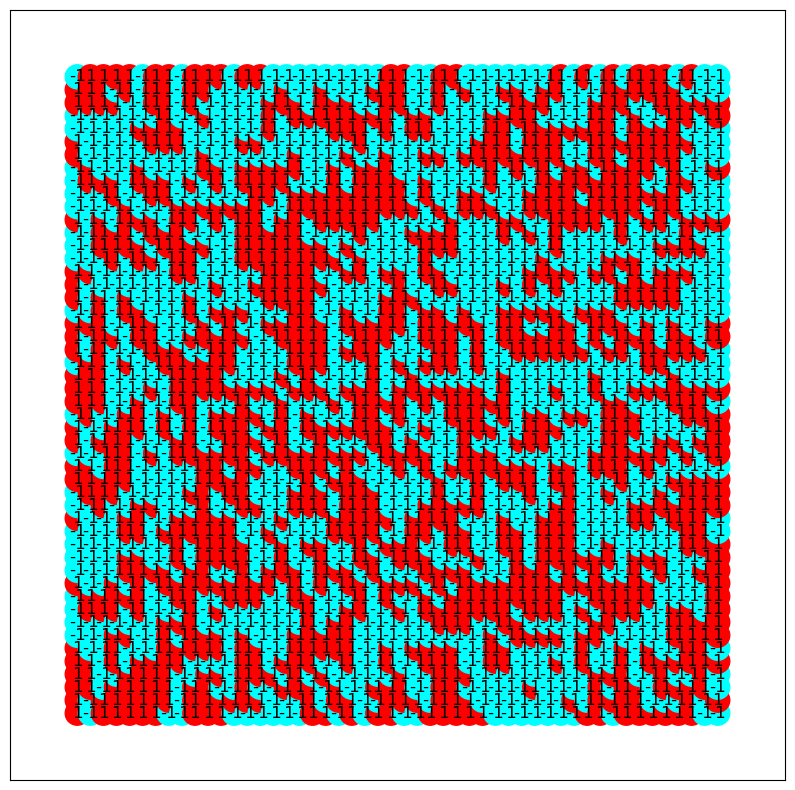

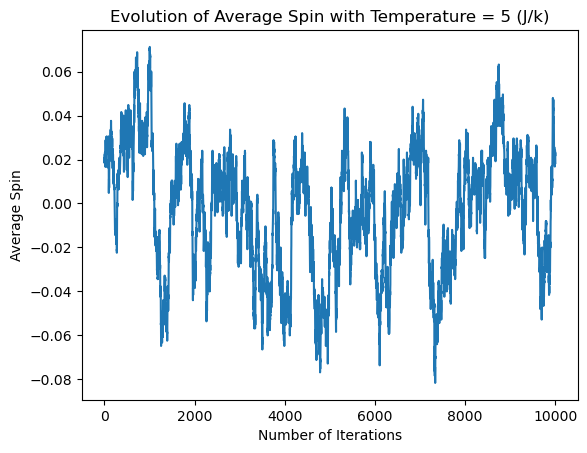

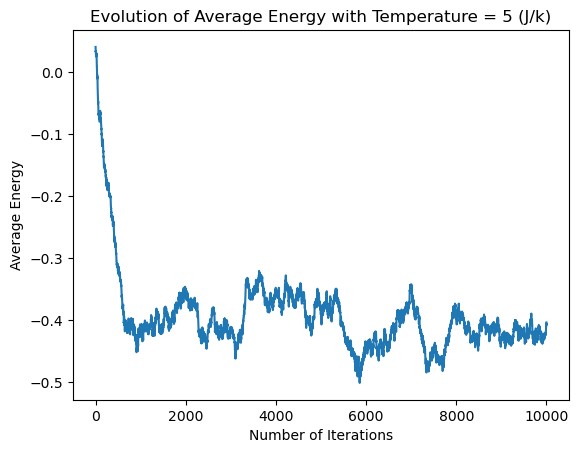

In [573]:
num_iterations = 10000
T_val = 5
J_val = 1
display_evolution = True

lat_arr, spin_arr, energy_arr = Wolff(lattice_r, num_iterations, J_val, T_val, display_evolution)

%matplotlib inline
# Display the lattice as a graph once the evolution of the iterations is finished
lat_graph, pos, color = lattice_array2graph(lat_arr)
plt.figure(figsize=(10,10))
node_labels = nx.get_node_attributes(lat_graph,'spin')
nx.draw_networkx_labels(lat_graph, pos, labels = node_labels)
nx.draw_networkx(lat_graph, pos = pos, node_color = color, with_labels=False)
plt.show()

# Graph the average spin
plt.plot(range(num_iterations+1), spin_arr/(N**2))
plt.xlabel('Number of Iterations')
plt.ylabel('Average Spin')
plt.title('Evolution of Average Spin with Temperature = ' + str(T_val) + ' (J/k)')
plt.show()

# Graph the average energy
plt.plot(range(num_iterations+1), energy_arr/(N**2))
plt.xlabel('Number of Iterations')
plt.ylabel('Average Energy')
plt.title('Evolution of Average Energy with Temperature = ' + str(T_val) + ' (J/k)')
plt.show()

Testing Again with $T=1.43(\frac{J}{k})$. Note the time elapsed is very large for only 100 iterations.

In [455]:
num_iterations = 100
T_val = 1.43
J_val = 1
display_evolution = False


start = time.time()
lat_arr, spin_arr, energy_arr = Wolff(lattice_r, num_iterations, J_val, T_val, display_evolution)
end = time.time()
print("Elapsed (with compilation) = %s" % (end - start))


Elapsed (with compilation) = 221.1770212650299


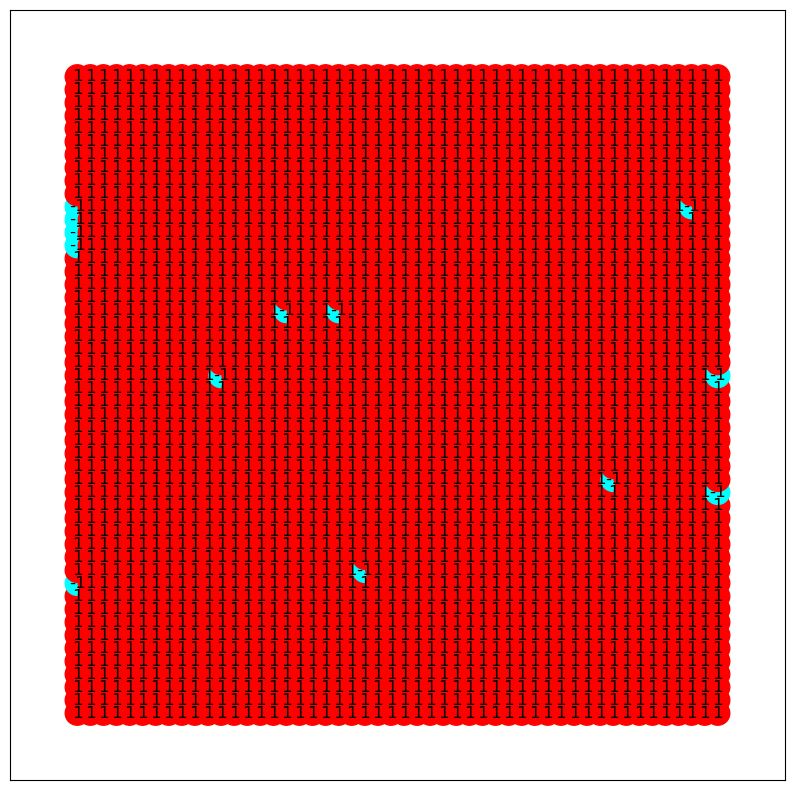

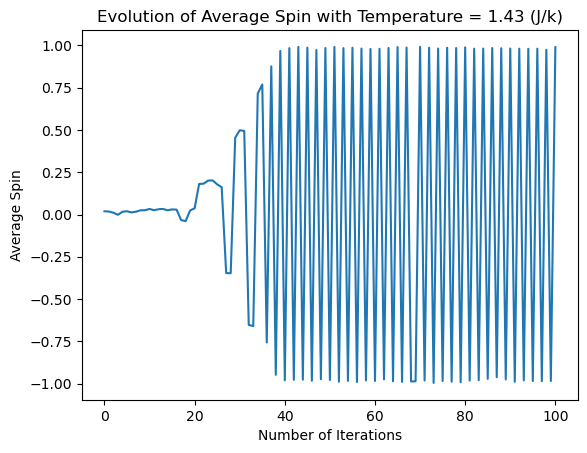

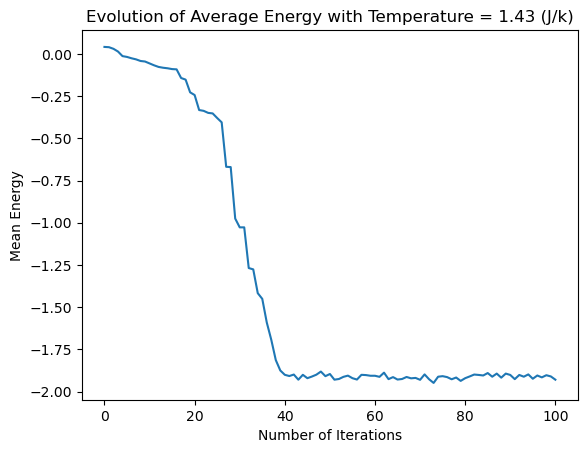

In [572]:
%matplotlib inline
# Display the lattice as a graph
lat_graph, pos, color = lattice_array2graph(lat_arr)
plt.figure(figsize=(10,10))
node_labels = nx.get_node_attributes(lat_graph,'spin')
nx.draw_networkx_labels(lat_graph, pos, labels = node_labels)
nx.draw_networkx(lat_graph, pos = pos, node_color = color, with_labels=False)
plt.show()

# Graph the spin
plt.plot(range(num_iterations+1), spin_arr/(N**2))
plt.xlabel('Number of Iterations')
plt.ylabel('Average Spin')
plt.title('Evolution of Average Spin with Temperature = ' + str(T_val) + ' (J/k)')
plt.show()

# Graph the energy
plt.plot(range(num_iterations+1), energy_arr/(N**2))
plt.xlabel('Number of Iterations')
plt.ylabel('Mean Energy')
plt.title('Evolution of Average Energy with Temperature = ' + str(T_val) + ' (J/k)')
plt.show()

From these two simulations, we can see that, for a large temperature, the mean spin will be zero; whereas, for a low temperature, the mean spin will oscillate between -1 and +1, meaning the magnitude of the mean spin will be 1. This aligns with expectations, since, for large temperatures, the lattice of spins will be disordered (and thus have a mean spin of 0), as seen in the graphs for T=5, and, for low temperatures, the lattice of spins will be ordered (and have a mean spin of magnitude 1), as seen in the graphs for T=1.43. We can plot mean spin with respect to temperature to find the phase transition point, or critical temperature, where the mean spin changes from zero to magnitude 1. 


NOTE: Prior to the critical temperature, large numbers of iterations will be very computationally expensive. We know that temperatures lower than the critical temperature will have a mean spin of (magnitude) one. So, for the sake of avoiding a very lengthy runtime (it would take days of running this code), I will create a variant of the Wolff function that keeps track of the magnitude of the last 5 average spins for each temperature iteration. The function will stop iterating at a certain temperature if the last 5 average spins were greater than 0.9 (1 with an error of 0.1). Also, it will return a boolean, stopped_early, which is true if it stopped early.

Here is the code for the Wolff_variant function. Note that most of it is the same as the regular Wolff function. The only difference is that it stops after 5 consecutive net spins of magnitude greater than 0.9.

In [19]:
########################################################################################
# Wolff_variant is the same as the Wolff, except it stops after 5 net spins greater    #
# than 0.9 in magnitude to avoid lengthy computations for low temperatures             #                                                               
# Inputs:                                                                              #
#    - lattice: an array containing spins of all electrons in the lattice              #
#    - iterations: the number of times to repeat step 6 before terminating             #
#    - J: The coupling constant                                                        #
#    - T: The temperature in J / k_B                                                   #
#    - show_lattice: boolean, will show the lattice evolving if true                   #
# Output:                                                                              #
#    - lattice_c: array of electron spins of the lattice after all iterations are done #
#    - net_spin: array of net electron spins at each iteration                         #
#    - net_energy: array containing net lattice energy for each iteration              #
#    - stopped_early: boolean, True if the algorithm stopped early                     #
#    - iterations_completed: the number of iterations the function did before stopping #
########################################################################################
@jit(parallel=True)
def Wolff_variant(lattice, iterations, J, T, show_lattice):
    # Wolff_variant function will stop iterating when net_spins_of_1 == 5
    net_spins_of_1 = 0                                           # Number of consecutive times abs(net_spin) >= 0.9
    stopped_early = False                                        # Did the function stop iterating early?
    stop_after = 5                                               # Max net_spins_of_1 before stopping
    
    # NOTE: beta = 1/(k_B*T), but we dont include k because T is in units of J/k_B
    BJ = J / T
    num_rows, num_cols = lattice.shape                           # Dimensions of the lattice
    prob = 1 - np.exp(-2 * BJ)                                   # Probability of forming bond with a neighboring particle
    net_spin = np.zeros(iterations+1)                            # Holds the net spin of the full lattice at each iteration
    net_energy = np.zeros(iterations+1)                          # Holds the total energy at each iteration
    lattice_c = np.copy(lattice)                                 # Copy the lattice so the original lattice is unaltered
    lattice_G = lattice_array2graph(lattice_c)[0]                # Lattice as a graph
    
    # Calculate the initial net_spin and net_energy
    # initial net_spin
    for node in lattice_G:
        net_spin[0] += lattice_G.nodes[node]['spin']
    
    # initial energy
    net_energy[0] = energy(lattice_c, J)
    
    if (show_lattice):
        # Display the lattice array
        plt.figure()
        plt.imshow(lattice_c)
    
    # Do step 6 repeatedely
    count = 0
    while (count < iterations and not stopped_early):
        # Choose a random particle in the lattice
        rand_row = np.random.randint(num_rows)
        rand_col = np.random.randint(num_cols)
        curr_point = [rand_row, rand_col]
        
        # Find the spin of the current particle
        # All spins in the cluster must be the same
        necessary_spin = lattice_c[curr_point[0]][curr_point[1]] 
        
        # Set the initial point to bonded
        lattice_G.nodes[tuple(curr_point)]['is_bonded'] = True
        
        ############################################################################################################
    
        ####################################################
        # Find the cluster and invert the electrons' spins #
        ####################################################
        
        particles_to_check = set()
        
        # Loop that computes the cluster and inverts spins
        continue_loop = True
        while (continue_loop and not stopped_early):
            # Get a dictionary containing the is_bonded status of every electron
            bond_status = nx.get_node_attributes(lattice_G, 'is_bonded')
            
            # Invert the spin of current particle
            lattice_c[curr_point[0]][curr_point[1]] = -1 * lattice_c[curr_point[0]][curr_point[1]]
            lattice_G.nodes[tuple(curr_point)]['spin'] = -1 * lattice_G.nodes[tuple(curr_point)]['spin']
                    
            # Get the coordinates for the top, bottom, left and right particles
            top = curr_point + np.asarray([1,0], dtype=np.int8)
            bottom = curr_point + np.asarray([-1,0], dtype=np.int8)
            right = curr_point + np.asarray([0,1], dtype=np.int8)
            left = curr_point + np.asarray([0,-1], dtype=np.int8)
            
            ##########################################
            # Top Particle                           #
            ##########################################
            
            # Make sure top particle is inside lattice
            if (top[0] < num_rows and top[1] < num_cols and top[0] >= 0 and top[1] >= 0):
                top_spin = lattice_c[top[0]][top[1]]

                # Run probability check for top particle & make sure it has not yet been checked & has necessary_spin & is not already part of the cluster
                if (np.random.random() <= prob and not (lattice_G[tuple(curr_point)][tuple(top)]['has_been_checked']) and top_spin == necessary_spin and not bond_status[tuple(top)]):
                    lattice_G.nodes[tuple(top)]['is_bonded'] = True
                    particles_to_check.add(tuple(top))
                    
                # We have finished checking the edge
                lattice_G[tuple(curr_point)][tuple(top)]['has_been_checked'] = True
                    
            ##########################################
            # Bottom Particle                        #
            ########################################## 
            
            # Make sure bottom particle is inside lattice
            if (bottom[0] < num_rows and bottom[1] < num_cols and bottom[0] >= 0 and bottom[1] >= 0):
                bottom_spin = lattice_c[bottom[0]][bottom[1]]

                # Run probability check for bottom particle & make sure it has not yet been checked & has necessary_spin & is not already part of the cluster
                if (np.random.random() <= prob and not (lattice_G[tuple(curr_point)][tuple(bottom)]['has_been_checked']) and bottom_spin == necessary_spin and not bond_status[tuple(bottom)]):
                    lattice_G.nodes[tuple(bottom)]['is_bonded'] = True
                    particles_to_check.add(tuple(bottom))
                    
                # We have finished checking the edge
                lattice_G[tuple(curr_point)][tuple(bottom)]['has_been_checked'] = True
                    
            ##########################################
            # Right Particle                         #
            ########################################## 
            
            # Make sure right particle is inside lattice
            if (right[0] < num_rows and right[1] < num_cols and right[0] >= 0 and right[1] >= 0):
                right_spin = lattice_c[right[0]][right[1]]

                # Run probability check for right particle & make sure it has not yet been checked & has necessary_spin & is not already part of the cluster
                if (np.random.random() <= prob and not (lattice_G[tuple(curr_point)][tuple(right)]['has_been_checked']) and right_spin == necessary_spin and not bond_status[tuple(right)]):
                    lattice_G.nodes[tuple(right)]['is_bonded'] = True
                    particles_to_check.add(tuple(right))
                    
                # We have finished checking the edge
                lattice_G[tuple(curr_point)][tuple(right)]['has_been_checked'] = True
            
            ##########################################
            # Left Particle                          #
            ########################################## 
            
            # Make sure left particle is inside lattice
            if (left[0] < num_rows and left[1] < num_cols and left[0] >= 0 and left[1] >= 0):
                left_spin = lattice_c[left[0]][left[1]]

                # Run probability check for left particle & make sure it has not yet been checked & has necessary_spin & is not already part of the cluster
                if (np.random.random() <= prob and not (lattice_G[tuple(curr_point)][tuple(left)]['has_been_checked']) and left_spin == necessary_spin and not bond_status[tuple(left)]):
                    lattice_G.nodes[tuple(left)]['is_bonded'] = True
                    particles_to_check.add(tuple(left))
                    
                # We have finished checking the edge
                lattice_G[tuple(curr_point)][tuple(left)]['has_been_checked'] = True
                                  
            # Stop the loop when there are no more particles to check
            if (len(particles_to_check) == 0):
                continue_loop = False
            else:
                curr_point = np.asarray(list(particles_to_check.pop()), dtype = np.int64)
        
        ############################################################################################################
        
        count = count + 1
        
        if(show_lattice):
            # Update the plot
            plt.imshow(lattice_c)
            plt.show()
            clear_output(wait=True)
        
        # Calculate the new net_spin and net_energy
        for node in lattice_G:
            net_spin[count] += lattice_G.nodes[node]['spin']
    
        net_energy[count] = energy(lattice_c, J)
        
        # Update net_spins_of_1
        if (abs(net_spin[count]/(num_rows*num_cols)) >= 0.9):
            net_spins_of_1 = net_spins_of_1 + 1
        else:
            # Reset net_spins_of_1 because it the number of spins is no longer consecutively >= 0.9
            net_spins_of_1 = 0
        
        # Stop iterating if maximum net spins of 1 is reached
        if (net_spins_of_1 >= stop_after):
            stopped_early = True
        
        # Reset the bonds
        for node in lattice_G.nodes:
            lattice_G.nodes[node]['is_bonded'] = False
            
        # Reset the Edges
        for edge in lattice_G.edges:
            lattice_G.edges[edge]['has_been_checked'] = False
     
    iterations_completed = count
    
    # Return the equilibrium state copy of the lattice
    return lattice_c, net_spin, net_energy, stopped_early, iterations_completed


Now we will run the simulation for 100 different temperatures between 0.05 and 5. This is because temperature can never reach absolute zero, so the minimum temperature to check must be larger than 0. From the previous run at T = 5 $(\frac{J}{k})$, we have seen that a temperature of 5 $\frac{J}{k}$ is above the critical temperature (because it has a mean spin of 0 at equilibrium), so that will be the maximum temperature we check.

NOTE: The spin at equilibrium is the most useful to us, so only the last 900 of 1000 iterations will be considered when taking the average spin, because that will give a closer value to the equilibrium than if all 1000 iterations were included in the average. This is because it takes time for the simulation to reach equilibrium, so the first 100 may not be representative of the equilibrium spin. For the low temperatures, the last 5 spins (which were all above 0.9) will have their average taken, because that would be the equilibrium for low temperatures.

The code below will run the simulation based on the necessary parameters. Note that it will take hours, depending on what values you choose. I ran the simulation, saved the data, and displayed the graph manually in the code block following the code below. However, if you would like to run the simulation yourself, then the code will display and update the graph automatically and you won't need to manually graph the data. Remember to click the power button at the top right of the graph window once the simulation is done, because if you don't then any future graphs will overlap on this one and ruin the graph.

In [37]:
%matplotlib notebook

# Choose the values of temperature we will simulate
starting_temp = 0.05
final_temp = 5
temps_to_check = 100
max_iterations_per_temperature = 1000

# Create a randomized 50x50 lattice of 50% +1 spin electrons and 50% -1 spin electrons
random_50x50 = np.random.random((50,50))
lattice_sim = np.zeros((50, 50))
lattice_sim[random_50x50 >= 0.5] = 1
lattice_sim[random_50x50 < 0.5]  = -1

# Create the arrays to hold the temperature (x-axis) and magnitude of mean spin (y-axis)
temperature_arr = np.linspace(starting_temp,final_temp,num=temps_to_check)
array_of_mean_spins = np.zeros(temps_to_check)

# Also create an array to hold net energies
array_of_energy = np.zeros((temps_to_check, max_iterations_per_temperature+1))

# Initialize the plot
fig,ax = plt.subplots(1,1)
ax.set_xlabel('Temperature (J/k)')
ax.set_ylabel('Average Spin')
ax.set_xlim(0,final_temp)

# Run the simulation for 100 temperature values
J_sim = 1
show_lattice = False
temporary_net_spin = np.zeros((temps_to_check, max_iterations_per_temperature+1))
for i in range(temps_to_check):
    # Get the values
    temporary_net_spin[i,:], array_of_energy[i,:], stopped_early, iterations_completed = Wolff_variant(lattice_sim, max_iterations_per_temperature, J_sim, temperature_arr[i], show_lattice)[1:]
    
    # Get the mean spin
    if (not stopped_early):
        # Use 900 (out of 1000) latest samples in mean calculation 
        array_of_mean_spins[i] = np.average(np.abs(temporary_net_spin[i, (iterations_completed-899):(iterations_completed+1)]/50**2))
    else:
        # Use latest 5 samples
        array_of_mean_spins[i] = np.average(np.abs(temporary_net_spin[i, (iterations_completed-4):(iterations_completed+1)]/ 50**2)) 
    
    # Update the plot
    ax.cla()
    ax.plot(temperature_arr, array_of_mean_spins, 'red')
    ax.set_xlabel('Temperature (J/k)')
    ax.set_ylabel('Average Spin')
    fig.canvas.draw()


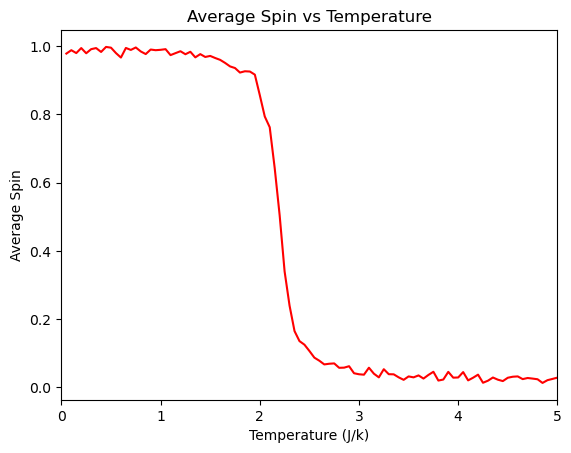

In [529]:
# Using the data I got from simulating it beforehand
fig,ax = plt.subplots(1,1)
plt.title('Average Spin vs Temperature')
ax.set_xlabel('Temperature (J/k)')
ax.set_ylabel('Average Spin')
ax.set_xlim(0,final_temp)

ax.plot(temperature_arr, array_of_mean_spins, 'red')
fig.canvas.draw()

The above simulation took roughly 4 hours to run, so the following code saves this important, computationally-expensive data:

In [31]:
# Save the data in a backup
save_spin_arr = array_of_mean_spins
save_net_spin_arr = temporary_net_spin
save_energy_arr = array_of_energy

np.set_printoptions(threshold=np.inf)
%store save_spin_arr >spin_arr.txt
%store save_net_spin_arr >net_spin_arr.txt
%store save_energy_arr >energy_arr.txt

%store save_spin_arr 
%store save_net_spin_arr 
%store save_energy_arr

Writing 'save_spin_arr' (ndarray) to file 'spin_arr.txt'.
Writing 'save_net_spin_arr' (ndarray) to file 'net_spin_arr.txt'.
Writing 'save_energy_arr' (ndarray) to file 'energy_arr.txt'.
Stored 'save_spin_arr' (ndarray)
Stored 'save_net_spin_arr' (ndarray)
Stored 'save_energy_arr' (ndarray)


In [32]:
%store

Stored variables and their in-db values:
save_energy_arr               -> array([[ 6.000e+01, -5.040e+02, -5.360e+02, -6.640
save_net_spin_arr             -> array([[ 3.000e+01,  2.120e+02,  2.180e+02,  2.480
save_spin_arr                 -> array([0.97856   , 0.98848   , 0.98      , 0.99472


<h2><center>Finding the Critical Temperature with Mean Spin</center></h2>

The zero of the 2nd derivative of average spin vs temperature (inflection points of mean spin vs temperature) will give us the critical temperature.

Finding the zero of the 2nd derivative:

<IPython.core.display.Javascript object>


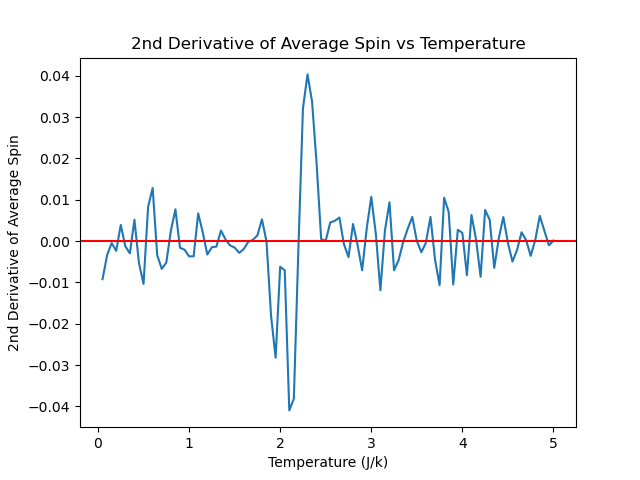

In [574]:
%matplotlib notebook

spin_2nd_deriv = np.gradient(np.gradient(array_of_mean_spins))


plt.plot(temperature_arr, spin_2nd_deriv)
plt.axhline(y=0, color='r', linestyle='-')
plt.title('2nd Derivative of Average Spin vs Temperature')
plt.xlabel('Temperature (J/k)')
plt.ylabel('2nd Derivative of Average Spin')
plt.show()

Note that there are many erroneous "inflection points" due to noise in the data. Visually, it seems that the most likely inflection point is somewhere between 2 and 3 ($\frac{J}{k}$), since there is a large amplitude of change. We can smoothen the data to ignore the noise and verify this.

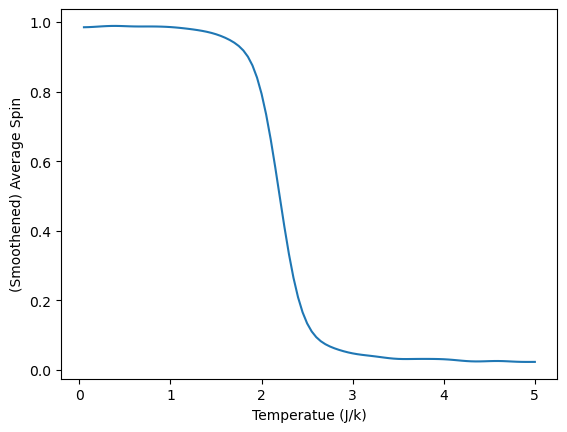

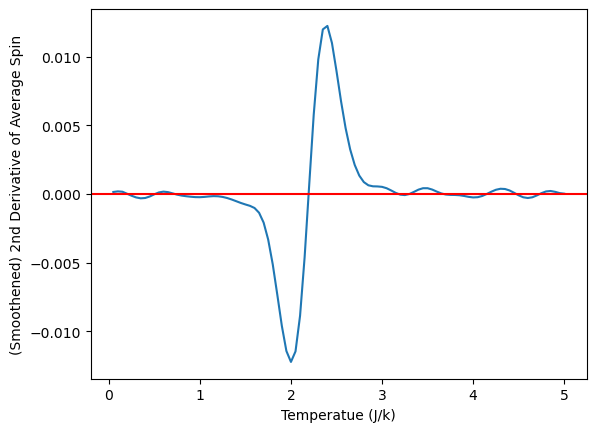

In [422]:
%matplotlib inline
from scipy.ndimage import gaussian_filter1d

smoothen_strength = 3

# Smoothen the original data
smooth_spin = gaussian_filter1d(array_of_mean_spins, smoothen_strength)

# Graph the smooth original data
plt.plot(temperature_arr, smooth_spin)
plt.title('(Smoothened) Average Spin vs Temperature')
plt.xlabel('Temperature (J/k)')
plt.ylabel('(Smoothened) Average Spin')
plt.show()

# Find the smoothened 2nd derivative
smooth_spin_2nd_deriv = np.gradient(np.gradient(smooth_spin))

# Graph the smoothened 2nd derivative
plt.plot(temperature_arr, smooth_spin_2nd_deriv)
plt.axhline(y=0, color='r', linestyle='-')
plt.xlabel('Temperature (J/k)')
plt.ylabel('(Smoothened) 2nd Derivative of Average Spin')
plt.show()

From the smoothened data, it is clear that the inflection point (critical temperature) is somewhere between 2 and 3, and all other "inflection points" are just noise and can be ignored. Here the code finds the inflection point.

In [94]:
#########################################
# Isolate to temperature in range [2,3] #
#########################################

# The equation to turn the temperature into the index is temperature / timestep - 1, - 1 because index 0 starts at
# timestep = 1. Since timestep = 0.05, this means index = temperature / 0.05 - 1
index_initial = 2 / 0.05 - 1
index_final   = 3 / 0.05 - 1

###########################################################
# Find index where smooth 2nd derivative goes from - to + #
###########################################################

continue_loop = True
curr_index = int(index_initial)
while(continue_loop):
    if (smooth_spin_2nd_deriv[curr_index] > 0):
        inflection_index = curr_index
        continue_loop = False
        
    elif (curr_index > index_final):
        continue_loop = False
    
    curr_index = curr_index + 1
    
######################################################
# Print the inflection point                         #
######################################################

inflection_point = inflection_index * 0.05 + 0.05
print('The inflection point is: {:.2f}'.format(inflection_point))

The inflection point is: 2.20


The inflection point, or the critical temperature of the 2D Ising Model, was calculated to be about 2.20 ($\frac{J}{k}$). 

Since the true known critical temperature is known to be 2.27 ($\frac{J}{k}$), we can find the percent error of this simulation:

In [102]:
percent_error = 100 * abs(inflection_point - 2.27) / 2.27

print('The critical temperature was calculated to be {:.2f}'.format(inflection_point), 'which was off by a {:.2f}'.format(percent_error), '% error.')

The critical temperature was calculated to be 2.20 which was off by a 3.08 % error.


<center>Here are the raw and smoothened graphs of average spin versus temperature, with the calculated and true critical temperatures noted in the graphs:</center>

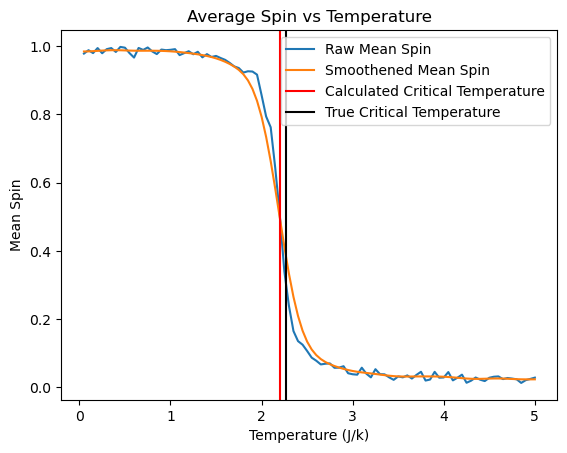

In [457]:
%matplotlib inline
# Create the plot
plt.figure()

plt.title('Average Spin vs Temperature')
plt.plot(temperature_arr, array_of_mean_spins, label='Raw Mean Spin')
plt.plot(temperature_arr, smooth_spin, label='Smoothened Mean Spin')
plt.xlabel('Temperature (J/k)')
plt.ylabel('Mean Spin')
plt.axvline(x=2.20, color='r', label='Calculated Critical Temperature')
plt.axvline(x=2.27, color='k', label='True Critical Temperature')
plt.legend()

plt.show()


<h2><center>Alternative Methods for Finding Critical Temperature</center></h2>

<h3>Susceptibility</h3>

With the mean spin we can calculate the susceptibility of the lattice with respect to temperature. The equation for the susceptibility, $\chi$, is:<br><br>


<center>$\chi=\frac{Var(Spin)}{T}$, where Var(Spin) is the variance of the spin.</center>

The susceptibility spikes at the critical temperature, so we can find the critical temperature by choosing the temperature corresponding to the spike in susceptibility. 

Note that as the temperature gets close to 0, $\chi$ increases rapidly because it gets close to dividing by zero. Additionally, because of the fact that only 5 iterations for low temperatures were computed to save time, there will be significantly more error for very low temperatures. So, I've only included the values corresponding to temperature in the range (1,5].

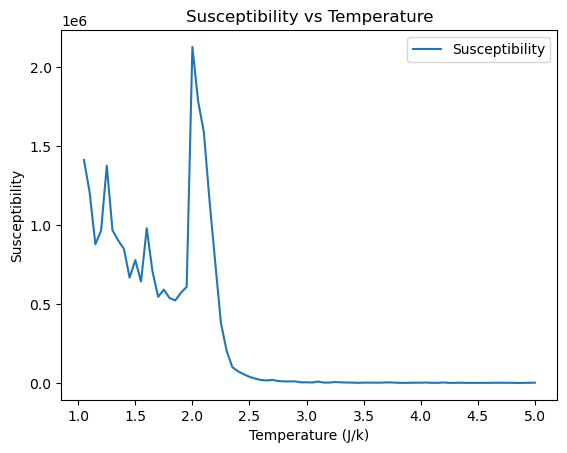

In [504]:
X = np.zeros(len(temporary_net_spin[:,0]))

for row in range(len(temporary_net_spin[:,0])): 
    non_zero = np.nonzero(temporary_net_spin[row,:])
    X[row] = np.var(temporary_net_spin[row, non_zero])/(temperature_arr[row])

plt.title('Susceptibility vs Temperature')
plt.plot(temperature_arr[20:], X[20:], label='Susceptibility')
plt.xlabel('Temperature (J/k)')
plt.ylabel('Susceptibility')
plt.legend()
plt.show()

If we had chosen to calculate the critical temperature using the susceptibility instead of mean spin, we would use the value of temperature where the susceptibility is the maximum.

In [464]:
# Get the max susceptibility where temperature > 1
max_sus = np.max(X[20:])

# Convert to an index
max_sus_index = int(np.where(X==max_sus)[0])

print('Alternative calculated critical temperature: {:.2f}'.format(temperature_arr[max_sus_index]))
print('Alternative calculated critical temperature error: {:.2f}'.format(100*abs(temperature_arr[max_sus_index]-2.27)/2.27),'%')

Alternative calculated critical temperature: 2.00
Alternative calculated critical temperature error: 11.89 %


<IPython.core.display.Javascript object>


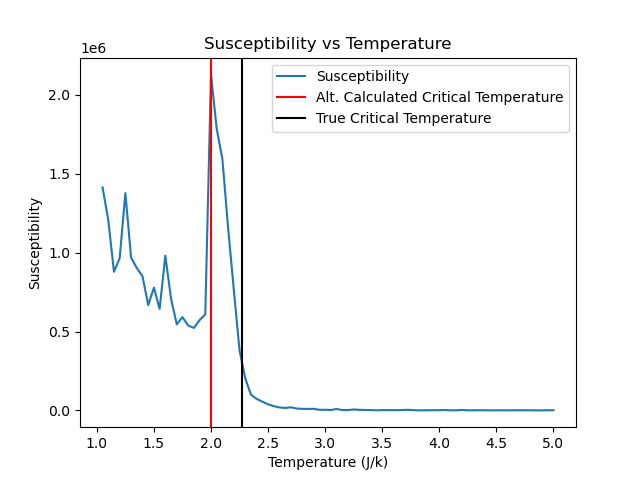

In [532]:
plt.title('Susceptibility vs Temperature')
plt.plot(temperature_arr[20:], X[20:], label='Susceptibility')
plt.xlabel('Temperature (J/k)')
plt.ylabel('Susceptibility')

plt.axvline(x=2, color='r', label='Alt. Calculated Critical Temperature')
plt.axvline(x=2.27, color='k', label='True Critical Temperature')
plt.legend()
plt.show()

<h3>Mean Energy</h3>

The mean energy (Energy / number of electrons = E/N^2) will be -2 below the critical temperature, and will begin increasing to 0 energy at the critical temperature. By finding the point where the mean energy begins to increase, we will find the critical temperature.

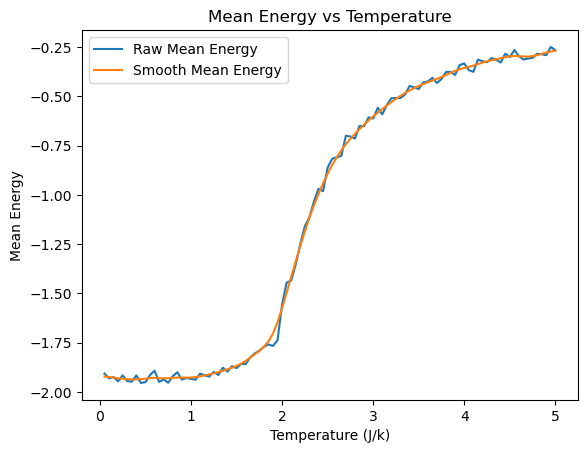

In [538]:
%matplotlib inline

# Clean & Wrangle the data
raw_energy = np.zeros(array_of_energy.shape[0])
non_zero_temp_energy = np.empty(array_of_energy.shape[1])
for row in range(len(array_of_energy[:,0])): 
    non_zero_temp_energy = array_of_energy[row, np.nonzero(array_of_energy[row])]
    # If the algorithm stopped early, only include the last 5 energies in the calculation
    # Otherwise, use all the energies
    if (non_zero_temp_energy.size < 900):
        raw_energy[row] = np.average(non_zero_temp_energy[0,non_zero_temp_energy.size-5:])
    else:
        
        raw_energy[row] = np.average(non_zero_temp_energy)

        
# Create the plot
plt.figure()
plt.title('Mean Energy vs Temperature')
plt.plot(temperature_arr, raw_energy/N**2, label='Raw Mean Energy')
smooth_energy = gaussian_filter1d(raw_energy, 2)
plt.plot(temperature_arr, smooth_energy/N**2, label='Smooth Mean Energy')
plt.xlabel('Temperature (J/k)')
plt.ylabel('Mean Energy')

plt.legend()
plt.show()

Finding the inflection point:

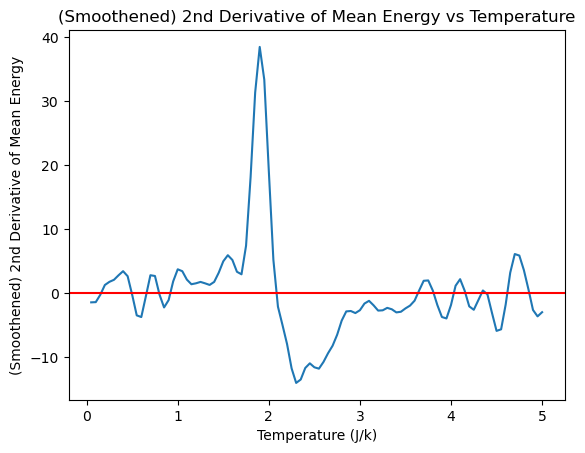

In [542]:
# Find the smoothened 2nd derivative
smooth_energy_2nd_deriv = np.gradient(np.gradient(smooth_energy))

# Graph the smoothened 2nd derivative
plt.plot(temperature_arr, smooth_energy_2nd_deriv)
plt.title('(Smoothened) 2nd Derivative of Mean Energy vs Temperature')
plt.axhline(y=0, color='r', linestyle='-')
plt.xlabel('Temperature (J/k)')
plt.ylabel('(Smoothened) 2nd Derivative of Mean Energy')
plt.show()

Zooming in to the temperature range of [1,3], where the change from + to - has the largest magnitude:

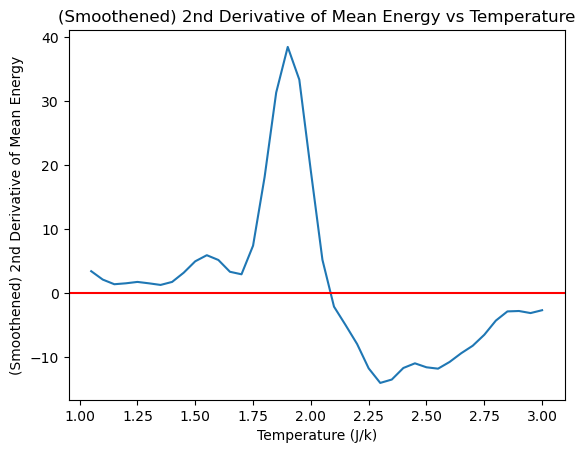

In [541]:
%matplotlib inline
# Graph the smoothened 2nd derivative on the temperature range [1,3]
plt.plot(temperature_arr[20:60], smooth_energy_2nd_deriv[20:60])
plt.axhline(y=0, color='r', linestyle='-')
plt.xlabel('Temperature (J/k)')
plt.ylabel('(Smoothened) 2nd Derivative of Mean Energy')
plt.title('(Smoothened) 2nd Derivative of Mean Energy vs Temperature')
plt.show()

Finding the zero:

In [536]:
#########################################
# Isolate to temperature in range [1,3] #
#########################################

index_initial = 1 / 0.05 - 1
index_final   = 3 / 0.05 - 1

##########################################################
# Find index where smooth 2nd derivativegoes from + to - #
##########################################################

continue_loop = True
curr_index = int(index_initial)
while(continue_loop):
    if (smooth_energy_2nd_deriv[curr_index] < 0):
        inflection_index = curr_index
        continue_loop = False
        
    elif (curr_index > index_final):
        continue_loop = False
    
    curr_index = curr_index + 1
    
######################################################
# Print the inflection point                         #
######################################################

inflection_point = inflection_index * 0.05 + 0.05
print('The inflection point is: {:.2f}'.format(inflection_point))

The inflection point is: 2.10


In [537]:
print('Alternative calculated critical temperature: {:.2f}'.format(inflection_point))
print('Alternative calculated critical temperature error: {:.2f}'.format(100*abs(inflection_point-2.27)/2.27),'%')

Alternative calculated critical temperature: 2.10
Alternative calculated critical temperature error: 7.49 %


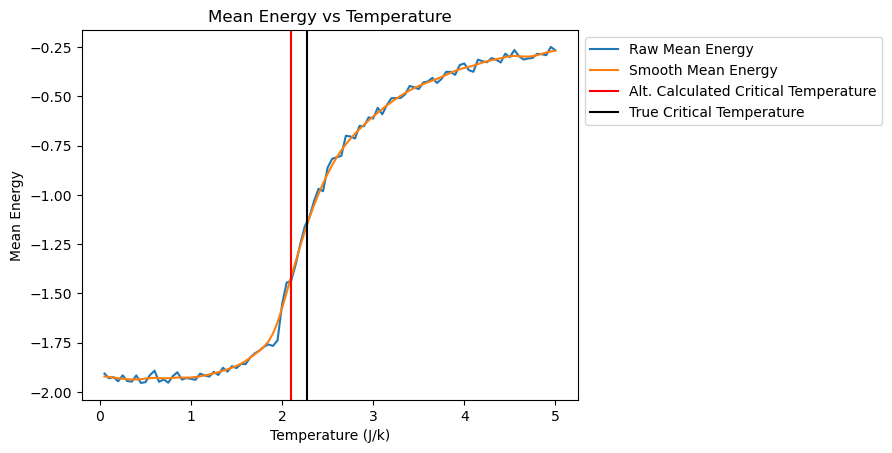

In [548]:
# Create the plot
plt.figure()
plt.title('Mean Energy vs Temperature')
plt.plot(temperature_arr, raw_energy/N**2, label='Raw Mean Energy')
smooth_energy = gaussian_filter1d(raw_energy, 2)
plt.plot(temperature_arr, smooth_energy/N**2, label='Smooth Mean Energy')
plt.axvline(x=2.1, color='r', label='Alt. Calculated Critical Temperature')
plt.axvline(x=2.27, color='k', label='True Critical Temperature')
plt.xlabel('Temperature (J/k)')
plt.ylabel('Mean Energy')

plt.legend(bbox_to_anchor=(1, 1))
plt.show()

<h3>Heat Capacity</h3>

We can calculate the critical temperative by finding the spike of the heat capacity. The value of the heat capacity can be found with the following equation:
<br><br>
<center>$C=\frac{Var(Energy)}{T^2}$, where Var(Energy) is the variance of the energy.</center>

<b>NOTE:</b> The factor of $\frac{1}{T^2}$ causes calculated values of C to diverge near 0, so only values in the temperature range (1,5] are included.

Alternative calculated critical temperature: 2.05
Alternative calculated critical temperature error: 9.69 %


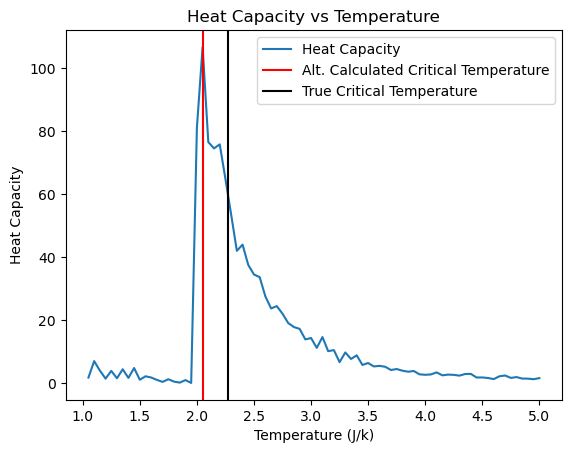

In [571]:
%matplotlib inline

#Clean & Wrangle the data
C = np.zeros(array_of_energy.shape[0])
non_zero_temp_energy = np.empty(array_of_energy.shape[1])
for row in range(len(array_of_energy[:,0])): 
    non_zero_temp_energy = array_of_energy[row, np.nonzero(array_of_energy[row])]
    
    # If the algorithm stopped early, only include the last 5 energies in the calculation
    # Otherwise, use all the energies
    if (non_zero_temp_energy.size < 900):
        C[row] = np.var(non_zero_temp_energy[0,non_zero_temp_energy.size-5:])/ (temperature_arr[row]**2)
    
    else:
        C[row] = np.var(non_zero_temp_energy) / (temperature_arr[row]**2)
        
# Calculate the critical temperature
# Get the max heat capacity where temperature > 1
max_C = np.max(C[20:]/N**2)

# Convert to an index

max_C_index = int(np.where(C[20:]/N**2==max_C)[0]) + 20 # Add 20 to account for the values in temperature range [0,1)

print('Alternative calculated critical temperature: {:.2f}'.format(temperature_arr[max_C_index]))
print('Alternative calculated critical temperature error: {:.2f}'.format(100*abs(temperature_arr[max_C_index]-2.27)/2.27),'%') 
        
# Create the plot
plt.figure()
plt.title('Heat Capacity vs Temperature')
plt.plot(temperature_arr[20:], C[20:]/N**2, label='Heat Capacity')
plt.xlabel('Temperature (J/k)')
plt.ylabel('Heat Capacity')

plt.axvline(x=temperature_arr[max_C_index], color='r', label='Alt. Calculated Critical Temperature')
plt.axvline(x=2.27, color='k', label='True Critical Temperature')

plt.legend()
plt.show()

<h2><center>Final Results: Summary</center></h2>

<center>For each of the following methods, several iterations of the Wolff Algorithm were used on a lattice of 50x50 electron spins at 100 temperatures between 0.05 and 5 to find how mean energy and mean spin change with respect to temperature.</center>

<h3>Mean Spin (Most Accurate)</h3>

The critical temperature, $T_c$, was calculated to be 2.20 $(\frac{J}{k})$ by finding the inflection point of average spin versus temperature. This approximation was off from the true value of 2.27 $(\frac{J}{k})$ by an error of 3.08%.

<h3>Susceptibility</h3>

The critical temperature, $T_c$, was calculated to be 2.00 by finding the temperature corresponding to the spike in susceptibility. This approximation was off from the true value of 2.27 $(\frac{J}{k})$ by an error of 11.89%.

<h3>Mean Energy</h3>

The critical temperature, $T_c$, was calculated to be 2.10 by finding the inflection point of average energy versus temperature. This approximation was off from the true value of 2.27 $(\frac{J}{k})$ by an error of 7.49%.

<h3>Heat Capacity</h3>

The critical temperature, $T_c$, was calculated to be 2.05 by finding the temperature corresponding to the spike in heat capacity. This approximation was off from the true value of 2.27 $(\frac{J}{k})$ by an error of 9.69%.

<h2><center>Resources</center></h2>
<center>Here are the resources I used to create this simulation. You may find them useful to learn more.</center>

"The Ising Model in Python: Statistical Mechanics and Permanent Magnets," Mr. P Solver: https://youtu.be/K--1hlv9yv0
<br><b>Note:</b> In his video, he implemented the Metropolis Algorithm. In this simulation, the Wolff Algorithm was used.

"Introduction to Cluster Monte Carlo Algorithms," by E. Luijten: https://csml.northwestern.edu/resources/Reprints/lnp_color.pdf. 
<br>

"The Ising Model," by Stanford: https://stanford.edu/~jeffjar/statmech/intro4.html.
<br>

"Programming with NetworkX in Python," by Mohammad T. Irfan: https://youtu.be/CPQeSmDGiOQ.
<br>

"A Guide to Monte Carlo Simulations in Statistical Physics: Fourth Edition," by David P. Landau and Kurt Binder
<br>

"Monte Carlo Simulations in the 2-dimensional Ising Model," by Anthony Bourached, supervised by Professor Stefan Sint: https://www.maths.tcd.ie/~bouracha/college/Trinity/Maths_Project/2-dimensional_ising_model.pdf